# 05 · Comparación y conclusiones

En este notebook juntamos los dos componentes. La sección 1 compara el aprendizaje supervisado con el no supervisado y responde las ocho preguntas de comparación del enunciado. Las estrategias para reducir las cancelaciones y las conclusiones van en las secciones 2 y 3.

## 1. Comparación entre aprendizaje supervisado y no supervisado

### 1.1 De dónde salen las cifras

Este notebook no vuelve a entrenar la SVM ni a repetir los análisis de los notebooks 03 y 04. La búsqueda de hiperparámetros de la SVM tardó más de una hora (notebook 03, sección 4.2), y los resultados ya están en los notebooks 03 y 04. Las tablas de la 1.2 copian esas cifras, y cada fila dice de qué notebook y sección sale, para que se puedan revisar.

Lo único que calculamos aquí es el cruce de la 1.3, porque necesita los dos enfoques sobre las mismas reservas y no está en ningún notebook anterior. Para ese cruce usamos la regresión logística, que se reentrena en segundos, y los segmentos de K-Means, que se rehacen igual con la misma semilla.

### 1.2 Resumen de métricas

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

sys.path.insert(0, str(Path("../src").resolve()))

from preprocesamiento import (
    COLUMNAS_PREDICTORAS,
    GRUPO,
    OBJETIVO,
    SEMILLA,
    crear_particionador,
    crear_preprocesador,
)

RUTA_ENTRENAMIENTO = Path("../data/processed/entrenamiento.csv.gz")
METRICAS = ["F1", "Recall", "Precision", "ROC-AUC", "PR-AUC"]

COLOR_PRINCIPAL = "#087F8C"
COLOR_SECUNDARIO = "#A0AEC0"
COLOR_RIESGO = "#916313"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 100)

In [2]:
resumen_supervisado = pd.DataFrame([
    ("Referencia: todas canceladas", "Validación cruzada", 0.452, 1.000, 0.292, 0.500, 0.292, "03 · 2.3"),
    ("Logística (C=1, corte 0,086)", "Validación cruzada", 0.573, 0.733, 0.470, 0.751, 0.553, "03 · 4.4"),
    ("SVM (C=3, gamma='scale', corte −0,009)", "Validación cruzada", 0.589, 0.750, 0.485, 0.767, 0.575, "03 · 4.4"),
    ("Logística (C=1, corte 0,086)", "Prueba", 0.575, 0.736, 0.471, 0.754, 0.559, "03 · 4.5"),
    ("SVM (C=3, gamma='scale', corte −0,009)", "Prueba", 0.590, 0.750, 0.486, 0.771, 0.579, "03 · 4.5"),
    ("Logística (corte 0)", "Llegadas de 2017", 0.548, 0.758, 0.430, 0.727, 0.482, "03 · 6.2"),
    ("SVM (corte 0)", "Llegadas de 2017", 0.555, 0.730, 0.447, 0.729, 0.483, "03 · 6.2"),
], columns=["modelo", "evaluación", *METRICAS, "fuente"])

print("Componente supervisado")
resumen_supervisado

Componente supervisado


,modelo,evaluación,F1,Recall,Precision,ROC-AUC,PR-AUC,fuente
0,Referencia: todas canceladas,Validación cruzada,0.452,1.000,0.292,0.500,0.292,03 · 2.3
1,"Logística (C=1, corte 0,086)",Validación cruzada,0.573,0.733,0.470,0.751,0.553,03 · 4.4
2,"SVM (C=3, gamma='scale', corte −0,009)",Validación cruzada,0.589,0.750,0.485,0.767,0.575,03 · 4.4
3,"Logística (C=1, corte 0,086)",Prueba,0.575,0.736,0.471,0.754,0.559,03 · 4.5
4,"SVM (C=3, gamma='scale', corte −0,009)",Prueba,0.590,0.750,0.486,0.771,0.579,03 · 4.5
5,Logística (corte 0),Llegadas de 2017,0.548,0.758,0.430,0.727,0.482,03 · 6.2
6,SVM (corte 0),Llegadas de 2017,0.555,0.730,0.447,0.729,0.483,03 · 6.2


In [3]:
resumen_agrupamiento = pd.DataFrame([
    ("K-Means", 4, "Entrenamiento completo (63.351)", 0.249, 1.392, 17407.5, 45.5, np.nan, "04 · 2.3"),
    ("K-Means", 4, "Muestra de 10.000", 0.247, 1.393, 2729.0, 46.15, 1.000, "04 · 3.5"),
    ("Ward", 3, "Muestra de 10.000", 0.280, 1.230, 2269.8, 76.81, 0.281, "04 · 3.5"),
    ("Ward", 4, "Muestra de 10.000", 0.189, 1.615, 2189.5, 48.73, 0.422, "04 · 3.5"),
], columns=["método", "k", "reservas", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz",
            "grupo más grande (%)", "ARI con K-Means (k = 4)", "fuente"])

resumen_segmentos = pd.DataFrame([
    ("Escapadas de fin de semana", 13.4, 21.6, 22.1, 9.9),
    ("Anticipadas y largas", 45.5, 34.6, 35.3, 54.0),
    ("Última hora entre semana", 25.5, 18.6, 18.9, 16.2),
    ("Viajes con menores", 15.5, 37.3, 34.5, 19.8),
    ("Todas las reservas", 100.0, 29.2, 29.2, 100.0),
], columns=["segmento de K-Means", "reservas (%)", "cancelación en entrenamiento (%)",
            "cancelación en prueba (%)", "aporte a las cancelaciones (%)"]).assign(fuente="04 · 4.1 y 4.3")

otras_cifras = pd.DataFrame([
    ("Cancelación en el CSV original (sin limpiar)", "37,0 %", "01 · 1.6"),
    ("Filas idénticas a otra en el CSV original", "31.994", "01 · 2.3"),
    ("Recall de la logística sin pesos de clase", "0,263", "03 · 2.3"),
    ("Reservas de ajuste que terminan como vectores de soporte (SVM)", "65,4 %", "03 · 3.3"),
    ("Perfiles de entrenamiento con reservas canceladas y no canceladas", "1.713 (4.030 reservas)", "03 · 3.3"),
    ("Cancelaciones de prueba que detecta la SVM", "3.470 de 4.628", "03 · 4.5"),
    ("Falsas alarmas de la SVM en prueba", "3.664 de 11.211 que sí llegaron", "03 · 4.5"),
    ("Memoria de la matriz de distancias de Ward con todas las reservas", "16,1 GB", "04 · 3.2"),
    ("ARI de los segmentos con otras muestras del 80 % (promedio y mínimo)", "0,991 y 0,975", "04 · 4.2"),
    ("ARI de los segmentos con otras semillas (9 de 10 / la que se sale)", "0,977 o más / 0,460", "04 · 4.2"),
    ("ARI entre el modelo de entrenamiento y un K-Means ajustado con la prueba", "0,961", "04 · 4.2"),
    ("V de Cramér entre segmento y cancelación", "0,170", "04 · 4.3"),
    ("Varianza que conservan los dos primeros componentes de PCA", "56,9 % (35,7 % y 21,2 %)", "04 · 5.1"),
    ("Conservación local con 15 vecinos (PCA / t-SNE)", "0,914 / 0,997", "04 · 5.2"),
], columns=["cifra", "valor", "fuente"])

print("Componente no supervisado")
display(resumen_agrupamiento)
print("Segmentos y cancelación (calculada después de agrupar)")
display(resumen_segmentos)
print("Otras cifras que usamos en las respuestas")
otras_cifras

Componente no supervisado


,método,k,reservas,Silhouette,Davies-Bouldin,Calinski-Harabasz,grupo más grande (%),ARI con K-Means (k = 4),fuente
0,K-Means,4,Entrenamiento completo (63.351),0.249,1.392,17407.5,45.50,NaN,04 · 2.3
1,K-Means,4,Muestra de 10.000,0.247,1.393,2729.0,46.15,1.000,04 · 3.5
2,Ward,3,Muestra de 10.000,0.280,1.230,2269.8,76.81,0.281,04 · 3.5
3,Ward,4,Muestra de 10.000,0.189,1.615,2189.5,48.73,0.422,04 · 3.5


Segmentos y cancelación (calculada después de agrupar)


,segmento de K-Means,reservas (%),cancelación en entrenamiento (%),cancelación en prueba (%),aporte a las cancelaciones (%),fuente
0,Escapadas de fin de semana,13.4,21.6,22.1,9.9,04 · 4.1 y 4.3
1,Anticipadas y largas,45.5,34.6,35.3,54.0,04 · 4.1 y 4.3
2,Última hora entre semana,25.5,18.6,18.9,16.2,04 · 4.1 y 4.3
3,Viajes con menores,15.5,37.3,34.5,19.8,04 · 4.1 y 4.3
4,Todas las reservas,100.0,29.2,29.2,100.0,04 · 4.1 y 4.3


Otras cifras que usamos en las respuestas


,cifra,valor,fuente
0,Cancelación en el CSV original (sin limpiar),"37,0 %",01 · 1.6
1,Filas idénticas a otra en el CSV original,31.994,01 · 2.3
2,Recall de la logística sin pesos de clase,"0,263",03 · 2.3
3,Reservas de ajuste que terminan como vectores de soporte (SVM),"65,4 %",03 · 3.3
4,Perfiles de entrenamiento con reservas canceladas y no canceladas,1.713 (4.030 reservas),03 · 3.3
5,Cancelaciones de prueba que detecta la SVM,3.470 de 4.628,03 · 4.5
6,Falsas alarmas de la SVM en prueba,3.664 de 11.211 que sí llegaron,03 · 4.5
7,Memoria de la matriz de distancias de Ward con todas las reservas,"16,1 GB",04 · 3.2
8,ARI de los segmentos con otras muestras del 80 % (promedio y mínimo),"0,991 y 0,975",04 · 4.2
9,ARI de los segmentos con otras semillas (9 de 10 / la que se sale),"0,977 o más / 0,460",04 · 4.2


### 1.3 Los dos enfoques sobre las mismas reservas

Las tablas muestran cada enfoque por su lado. Falta una pregunta que solo se responde juntándolos: **¿el modelo supervisado distingue el riesgo dentro de cada segmento, o el segmento ya dice todo lo que el modelo sabe?** Si el segmento bastara, al hotel le daría lo mismo usar uno u otro.

Para responderla, a cada reserva de entrenamiento le ponemos dos cosas:

- **Su segmento de K-Means.** Repetimos la preparación y el K-Means de la sección 2 del notebook 04, con la misma semilla, y comprobamos que salen exactamente los mismos tamaños.
- **Su puntaje de riesgo de la logística**, con `C=1`, pesos balanceados y el corte de 0,086 de la sección 4.3 del notebook 03. Usamos predicciones fuera de partición: el puntaje de cada reserva sale de un modelo que no la vio, entrenado en las mismas cinco particiones agrupadas del notebook 03. Así no tocamos la prueba, que ya se usó.

Usamos la logística y no la SVM porque esta se demora mucho más en reentrenarse. En prueba la logística queda apenas 0,015 de F1 por debajo de la SVM (tabla de la 1.2), así que para este cruce es una buena aproximación.

In [4]:
TAMANOS_SEGMENTOS_NOTEBOOK_04 = [8497, 28852, 16156, 9846]
NOMBRES_SEGMENTOS = {
    0: "Escapadas de fin de semana",
    1: "Anticipadas y largas",
    2: "Última hora entre semana",
    3: "Viajes con menores",
}
CORTE_LOGISTICA = 0.086
CUARTOS_RIESGO = ["1 · el 25 % de menor riesgo", "2", "3", "4 · el 25 % de mayor riesgo"]


def segmentos_de_kmeans(datos):
    """Rehace la preparación y el K-Means (k = 4) de la sección 2 del notebook 04."""
    variables = datos.assign(
        proporcion_fin_semana=datos["stays_in_weekend_nights"] / datos["total_noches"],
        con_menores=(datos["children"] + datos["babies"]).gt(0).astype(int),
    )
    preparador = ColumnTransformer([
        ("logaritmo", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()),
         ["lead_time", "total_noches", "total_huespedes"]),
        ("escaladas", StandardScaler(), ["proporcion_fin_semana"]),
        ("binarias", "passthrough", ["con_menores"]),
        ("categoricas", OneHotEncoder(min_frequency=0.01, handle_unknown="infrequent_if_exist", sparse_output=False),
         ["customer_type", "distribution_channel"]),
    ])
    matriz = preparador.fit_transform(variables)
    return KMeans(n_clusters=4, n_init=10, random_state=SEMILLA).fit_predict(matriz)


entrenamiento = pd.read_csv(RUTA_ENTRENAMIENTO)
X_entrenamiento = entrenamiento[list(COLUMNAS_PREDICTORAS)]
y_entrenamiento = entrenamiento[OBJETIVO]

segmentos = segmentos_de_kmeans(entrenamiento)
assert np.bincount(segmentos).tolist() == TAMANOS_SEGMENTOS_NOTEBOOK_04

logistica = Pipeline([
    ("preprocesamiento", crear_preprocesador()),
    ("modelo", LogisticRegression(class_weight="balanced", max_iter=1_000, random_state=SEMILLA)),
])
particiones = list(crear_particionador().split(X_entrenamiento, y_entrenamiento, entrenamiento[GRUPO]))
puntaje = cross_val_predict(logistica, X_entrenamiento, y_entrenamiento, cv=particiones, method="decision_function")
marcada = puntaje > CORTE_LOGISTICA

print("Segmentos iguales a los del notebook 04:", np.bincount(segmentos).tolist())
print(f"Logística fuera de partición: F1 {f1_score(y_entrenamiento, marcada):.3f}, "
      f"Recall {recall_score(y_entrenamiento, marcada):.3f}, Precision {precision_score(y_entrenamiento, marcada):.3f}, "
      f"ROC-AUC {roc_auc_score(y_entrenamiento, puntaje):.3f}, marcadas {marcada.mean():.1%}")

Segmentos iguales a los del notebook 04: [8497, 28852, 16156, 9846]
Logística fuera de partición: F1 0.573, Recall 0.733, Precision 0.470, ROC-AUC 0.751, marcadas 45.6%


Los segmentos salen idénticos a los del notebook 04, y la logística da las mismas cifras de la sección 4.3 del notebook 03 (F1 de 0,573 y 45,6 % de reservas marcadas). Con eso, medimos el modelo dentro de cada segmento.

,reservas,cancelación (%),ROC-AUC dentro del segmento,marcadas como canceladas (%),Recall,Precision,cancelaciones detectadas que aporta (%)
Escapadas de fin de semana,8497.0,21.643,0.718,29.081,0.543,0.404,7.358
Anticipadas y largas,28852.0,34.649,0.741,57.022,0.808,0.491,59.584
Última hora entre semana,16156.0,18.612,0.723,22.004,0.470,0.397,10.417
Viajes con menores,9846.0,37.254,0.710,64.788,0.837,0.481,22.641
Todas las reservas,63351.0,29.220,0.751,45.551,0.733,0.470,100.000


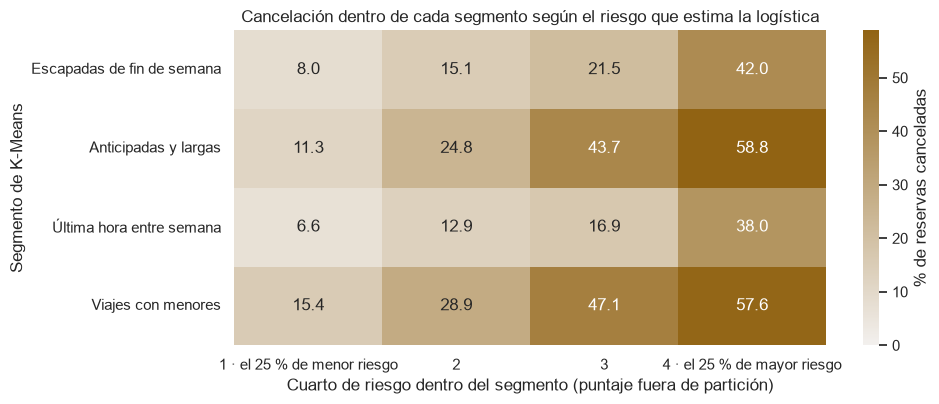

In [5]:
def modelo_en_segmento(mascara):
    """Cancelación observada y desempeño de la logística en un grupo de reservas."""
    reales, puntajes, marcas = y_entrenamiento[mascara], puntaje[mascara], marcada[mascara]
    return {
        "reservas": int(mascara.sum()),
        "cancelación (%)": reales.mean() * 100,
        "ROC-AUC dentro del segmento": roc_auc_score(reales, puntajes),
        "marcadas como canceladas (%)": marcas.mean() * 100,
        "Recall": recall_score(reales, marcas),
        "Precision": precision_score(reales, marcas),
        "cancelaciones detectadas que aporta (%)": (marcas & reales.eq(1).to_numpy()).sum()
        / (marcada & y_entrenamiento.eq(1).to_numpy()).sum() * 100,
    }


modelo_por_segmento = pd.DataFrame({
    **{nombre: modelo_en_segmento(segmentos == numero) for numero, nombre in NOMBRES_SEGMENTOS.items()},
    "Todas las reservas": modelo_en_segmento(np.ones(len(segmentos), dtype=bool)),
}).T
display(modelo_por_segmento.round(3))

riesgo = pd.DataFrame({
    "segmento": pd.Series(segmentos).map(NOMBRES_SEGMENTOS),
    "puntaje": puntaje,
    "cancelada": y_entrenamiento.to_numpy(),
})
riesgo["cuarto de riesgo"] = riesgo.groupby("segmento")["puntaje"].transform(
    lambda valores: pd.qcut(valores, q=len(CUARTOS_RIESGO), labels=CUARTOS_RIESGO).astype(str)
)
cancelacion_por_cuarto = (
    riesgo.pivot_table(index="segmento", columns="cuarto de riesgo", values="cancelada", aggfunc="mean")
    .loc[list(NOMBRES_SEGMENTOS.values()), CUARTOS_RIESGO] * 100
)

fig, ax = plt.subplots(figsize=(10, 4.2))
sns.heatmap(cancelacion_por_cuarto, cmap=sns.light_palette(COLOR_RIESGO, as_cmap=True), annot=True, fmt=".1f",
            vmin=0, cbar_kws={"label": "% de reservas canceladas"}, ax=ax)
ax.set_title("Cancelación dentro de cada segmento según el riesgo que estima la logística")
ax.set_xlabel("Cuarto de riesgo dentro del segmento (puntaje fuera de partición)")
ax.set_ylabel("Segmento de K-Means")
plt.tight_layout()
plt.show()

**¿Qué vemos?**

- **El modelo sigue separando el riesgo dentro de cada segmento.** Su ROC-AUC dentro de cada uno va de 0,710 (viajes con menores) a 0,741 (anticipadas y largas), apenas por debajo del 0,751 con todas las reservas juntas. En el mapa se ve lo que eso significa: dentro de las anticipadas, el cuarto de menor riesgo cancela 11,3 % y el de mayor riesgo 58,8 %; dentro de las de última hora, 6,6 % contra 38,0 %. Esas diferencias son mucho más grandes que las que hay entre segmentos, que van de 18,6 % a 37,3 %. O sea que el segmento no reemplaza al puntaje: dos reservas del mismo segmento pueden tener riesgos muy distintos.
- **El segmento, a su vez, muestra dónde se concentra el riesgo.** Con un solo corte, la logística marca el 57,0 % de las anticipadas y el 64,8 % de los viajes con menores, pero solo el 29,1 % de las escapadas y el 22,0 % de las de última hora. De las cancelaciones que el modelo detecta, el 82,2 % sale de esos dos primeros segmentos (59,6 % y 22,6 %).
- **Ese único corte deja algo por fuera.** En los dos segmentos de poca anticipación el modelo detecta apenas la mitad de las cancelaciones (Recall de 0,543 en las escapadas y de 0,470 en las de última hora), contra 0,808 y 0,837 en los otros dos. No es que ahí ordene mal, porque su ROC-AUC es parecido; es que la mayoría de esas reservas queda por debajo del corte. Si al hotel le importan las cancelaciones de esos perfiles, una opción es un corte por segmento, escogido con validación cruzada como en la 4.3 del notebook 03.

Lo que esto no permite concluir: el cruce es con la logística y con puntajes fuera de partición del entrenamiento, no con la SVM ni con la prueba. Con la SVM los números cambiarían algo, pero no lo medimos.

### 1.4 Respuestas a las ocho preguntas

**1. ¿Qué problema busca resolver el componente supervisado y qué problema busca resolver el no supervisado?**

El supervisado responde una pregunta sobre **cada reserva**: cuando entra, ¿qué tan probable es que se cancele? Aprende de reservas pasadas cuyo desenlace ya se conoce (`is_canceled`) y solo puede usar lo que se sabe al momento de reservar. El no supervisado responde una pregunta sobre **el conjunto**: ¿qué tipos de reservas recibe el hotel? Agrupa las reservas por cómo son (anticipación, duración, fin de semana, huéspedes, tipo de cliente y canal) sin mirar si se cancelaron. El primero sirve para actuar sobre una reserva concreta; el segundo, para entender a quién le vende el hotel y diseñar políticas por perfil.

**2. ¿Cuáles fueron los algoritmos seleccionados y por qué se consideran apropiados para el conjunto de datos?**

En el supervisado, los dos con pesos de clase balanceados, porque solo se cancela el 29,2 % de las reservas:

- **Regresión logística.** Es el modelo base natural para una clasificación binaria, se puede interpretar con sus coeficientes, es rápida y ordena las reservas por riesgo. Su limitación quedó medida: supone una relación lineal con el logit, y la anticipación no la cumple (notebook 03, sección 2.2).
- **Máquina de vectores de soporte con kernel RBF.** Reemplazó al bosque aleatorio del plan inicial (notebook 03, sección 3.1). Su frontera curva puede seguir relaciones no lineales e interacciones sin construirlas a mano, y el margen con `C` controla el sobreajuste. A cambio, no tiene coeficientes, no da probabilidades y es lenta.

En el no supervisado:

- **K-Means.** Trabaja con las 63.351 reservas de entrenamiento, ubica una reserva nueva en su segmento y su centro funciona como "la reserva típica", fácil de explicar. Supone grupos compactos y de tamaño parecido, y por eso preparamos las variables con logaritmo y escalas comparables (notebook 04, sección 1.4).
- **Agrupamiento jerárquico con enlace de Ward.** No hay que fijar *k* antes, no depende del punto de partida y minimiza la misma inercia que K-Means, así que los dos se comparan con las mismas medidas. Necesita todas las distancias entre pares de reservas, 16,1 GB con todo el entrenamiento, y por eso se aplicó sobre una muestra de 10.000.

Para ver los segmentos en dos dimensiones usamos PCA y t-SNE.

**3. ¿Qué dificultades se presentaron durante el entrenamiento y evaluación de los modelos?**

- **Fuga de información.** Varias columnas revelan el desenlace o se llenan después de reservar, como `reservation_status`, `assigned_room_type` o `booking_changes`. Las sacamos, y con ellas otras dudosas: el depósito, el país, la tarifa, los pedidos especiales y el parqueadero. El modelo quedó con poca información, que es la razón principal de que su desempeño sea moderado.
- **Duplicados sin identificador de reserva.** El CSV tenía 31.994 filas idénticas a otra. Al limpiarlas, la cancelación pasó de 37,0 % a 29,2 %, y hubo que partir los datos por perfil de reserva para que dos reservas iguales no quedaran una en ajuste y otra en validación.
- **Desbalance de clases.** Sin pesos, la logística solo detectaba el 26,3 % de las cancelaciones (Recall de 0,263).
- **Clases muy traslapadas.** El 65,4 % de las reservas de ajuste terminaron como vectores de soporte de la SVM, y hay 1.713 perfiles con exactamente las mismas entradas en los que unas reservas se cancelaron y otras no. Por eso la búsqueda de hiperparámetros mejoró poco: ningún ajuste separa lo que los datos no separan.
- **Costo de cómputo.** La búsqueda de la SVM tardó más de una hora, y Ward no cabía en memoria con todas las reservas.
- **En el agrupamiento, ningún *k* se imponía.** Las cuatro medidas no coincidían y el Silhouette quedó cerca de 0,25 para cualquier *k*, así que escogimos *k* = 4 por la utilidad de los segmentos. Además, una de diez semillas llevó a K-Means a un mínimo local peor (ARI de 0,460).
- **Variables mixtas.** La distancia euclidiana mezcla numéricas y categorías en 0 y 1, y en ella el tipo de cliente terminó pesando poco.

**4. ¿El modelo supervisado logró identificar correctamente los casos de interés? ¿Qué métricas respaldan esta conclusión?**

En parte. La SVM, que fue el modelo escogido, detecta en prueba 3.470 de las 4.628 cancelaciones (Recall de 0,750), y de las reservas que marca se cancela el 48,6 % (Precision de 0,486), con un F1 de 0,590. Le gana a marcar todo como cancelado (F1 de 0,452 y Precision de 0,292), y su PR-AUC de 0,579 casi duplica la tasa de cancelación de 0,292, que es lo que daría ordenar las reservas al azar. Su ROC-AUC de 0,771 dice que, en general, pone las canceladas por encima de las que llegan. Además, las cifras de prueba son casi iguales a las de validación cruzada, así que la estimación es confiable para reservas como las del histórico.

Pero se le escapa una de cada cuatro cancelaciones y da 3.664 falsas alarmas entre 11.211 reservas que sí llegaron. Y en el ejercicio con llegadas de 2017 su ROC-AUC fue de 0,729; el notebook 03 advierte que esa caída no se puede atribuir solo al paso del tiempo, pero es una alerta. Conclusión: el modelo identifica bien dónde está el riesgo y sirve para priorizar, pero no acierta lo suficiente como para decidir sobre una reserva sola.

**5. ¿El modelo no supervisado descubrió estructuras o patrones que no eran evidentes inicialmente?**

Algunos sí. Que la anticipación y la duración separaran las reservas era de esperar después del análisis exploratorio. Lo que no era evidente:

- Que el tipo de cliente casi no separe las reservas, aunque el enunciado lo propone como dimensión de segmentación.
- Que los perfiles se distingan también en variables que no entraron al agrupamiento. Las reservas de última hora entre semana tienen más reservas sin agencia, con empresa y de clientes repetidos, lo que sugiere viajes de trabajo, aunque el dataset no dice para qué es el viaje; los viajes con menores se concentran en julio y agosto (notebook 04, sección 4.1).
- Que dos algoritmos que funcionan distinto encuentren los mismos dos núcleos: estancias cortas entre semana con muy poca anticipación y estancias cortas de fin de semana. Esos dos perfiles sí parecen estar en los datos.

Pero la estructura es débil. El Silhouette es de 0,249 en K-Means y de 0,280 en Ward, y los dos métodos coinciden poco (ARI de 0,281). Las reservas forman más un continuo que grupos separados. Lo que sí es firme es la partición de K-Means: sale casi igual con otras muestras (ARI de 0,991) y con reservas que no vio (ARI de 0,961).

**6. Si el conjunto de datos contiene etiquetas conocidas, ¿qué relación existe entre dichas etiquetas y los grupos encontrados?**

`is_canceled` no entró al agrupamiento, y aun así los segmentos se relacionan con ella. Dos cancelan por encima del promedio de 29,2 %, los viajes con menores (37,3 %) y las anticipadas y largas (34,6 %), y dos por debajo, las escapadas de fin de semana (21,6 %) y las de última hora entre semana (18,6 %). En prueba se mantienen las dos parejas, aunque entre los dos de arriba el orden se invierte. La relación es real pero débil, con una V de Cramér de 0,170: ningún segmento es "el de las canceladas". Coincide con el supervisado en lo principal: los segmentos que más cancelan son los que se reservan con más anticipación, y la anticipación es una de las variables que más usa la SVM (notebook 03, sección 5).

El cruce de la 1.3 completa la respuesta: dentro de cada segmento el riesgo sigue variando mucho, así que el segmento resume a qué tipo de reserva pertenece una cancelación, pero no cuál reserva se va a cancelar.

**7. ¿Qué información se conserva o se pierde al aplicar técnicas de reducción de dimensionalidad?**

- **PCA** conserva en dos componentes el 56,9 % de la varianza de la matriz del agrupamiento: el primero (35,7 %) resume la anticipación, las noches y los huéspedes, y el segundo (21,2 %) la proporción de fin de semana. Se pierde el 43,1 %, sobre todo el tipo de cliente y el canal, que tienen cargas cercanas a cero en los dos ejes (notebook 04, sección 5.1). En el plano se distinguen bien las escapadas y las de última hora, pero las anticipadas y los viajes con menores se montan.
- **t-SNE** conserva casi perfectamente qué reservas son vecinas (0,997 contra 0,914 de PCA), pero pierde las distancias globales: el tamaño de las islas y la distancia entre ellas dependen de la proyección y no se pueden leer como tamaños ni distancias reales, sus ejes no se pueden interpretar y el resultado depende de la muestra y de la perplejidad.
- En ninguno de los dos planos las canceladas se separan de las no canceladas. Es el mismo traslape que limitó al modelo supervisado, visto desde otro lado.

Las dos técnicas sirvieron para mirar los segmentos, no para definirlos: los segmentos se armaron con las 13 columnas completas.

**8. ¿Qué modelo o enfoque recomendaría el grupo para una aplicación real?**

Los dos enfoques juntos, porque responden preguntas distintas y el cruce de la 1.3 muestra que se complementan:

1. **Un modelo supervisado que ordene cada reserva por riesgo cuando entra.** La SVM es la que mejor lo hace: en prueba gana en todas las métricas (F1 de 0,590 contra 0,575 y ROC-AUC de 0,771 contra 0,754). La diferencia es pequeña, y la logística tiene ventajas que en un hotel pesan: explica sus decisiones con coeficientes y se reentrena en segundos. Si el hotel necesita justificarle a un cliente por qué le pide una garantía, o reentrenar con frecuencia, la logística es una opción razonable.
2. **Usar ese puntaje para priorizar acciones de bajo costo, no para decidir solo.** De cada dos reservas marcadas, una sí llega (Precision de 0,486). El corte debe salir de los costos reales del hotel, como propone la sección 4.6 del notebook 03, y no del F1.
3. **Los segmentos de K-Means para repartir la atención y diseñar políticas por perfil.** Las anticipadas y largas y los viajes con menores juntan el 73,8 % de las cancelaciones (54,0 % y 19,8 %). Dentro de cada segmento, el puntaje dice a qué reservas atender primero. Preferimos K-Means a Ward porque usa todas las reservas, puede ubicar las nuevas y reparte las reservas en grupos de tamaño útil (el grupo más grande de Ward tiene el 76,81 % de la muestra).
4. **Validar con reservas nuevas antes de usarlo.** Los datos son de dos hoteles de Portugal entre 2015 y 2017, y el ejercicio con llegadas de 2017 ya mostró una caída en el ROC-AUC.

Las estrategias concretas para cada perfil están en la sección 2.